# Кейс 3. Прогноз отклика клиентов на банковский депозит (бинарная классификация)

Цель - построить baseline-модель, которая предсказывает, откроет ли клиент депозит. Модель оцениваем по `PR-AUC` и `Lift`: колл-центр должен звонить в первую очередь тем клиентам, у которых шанс согласия выше, чтобы конверсия росла, а операторы тратили меньше звонков впустую.

План работы:
1. Подготовка данных: удаляем дубликаты и признак, через который в модель утекает информация о результате звонка. Выделяем holdout-выборку.
2. Новые признаки: строим их внутри пайплайна, чтобы кросс-валидация не давала завышенных оценок.
3. Обучение: собираем `Pipeline` и настраиваем логистическую регрессию через `GridSearchCV` со строгой кросс-валидацией. 
4. Порог: подбираем порог классификации по `Out-Of-Fold` предсказаниям и проверяем метрики на отложенной тестовой выборке.
5. Интерпретация: анализируем веса признаков по линейной модели и визуализируем конверсию.

In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, roc_auc_score, average_precision_score,
    precision_recall_curve, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)

sns.set_theme(style='whitegrid', context='notebook')

df = pd.read_csv('bank-additional-full.csv', sep=';').drop_duplicates()
print(f"Размер датасета после очистки: {df.shape}")

Размер датасета после очистки: (41176, 21)


## 1. Подготовка признаков и разбиение на выборки

Главное на этом этапе - не допустить утечки данных.

Признак `duration` (длительность звонка) удаляем. До разговора его длительность неизвестна. С этим признаком метрики выходят почти идеальными, но на новых клиентах такая модель работать не будет.

Новые признаки (агрегаты, взаимодействия экономических показателей, обработку значения 999 в `pdays`) считаем внутри собственного класса `BankFeatureEngineer`. Тогда при кросс-валидации и поиске по сетке (GridSearch) агрегаты считаются только на обучающих фолдах, и данные проверочного фолда в них не попадают.

Оговорка: для логистической регрессии `BankFeatureEngineer` стоит внутри пайплайна, и это условие выполняется. 

Класс `BankFeatureEngineer` наследуется от `BaseEstimator` и `TransformerMixin` из `sklearn.base`, чтобы его можно было встроить как обычный шаг в `Pipeline` и `GridSearchCV`. Наследование автоматически добавляет нужные для sklearn методы (`get_params`, `set_params`, `fit_transform`), поэтому достаточно прописать свою логику в `fit` (расчет средних и частот только на обучающих фолдах) и `transform` (создание новых колонок).

1.  **Предыдущие контакты и лояльность:**
*   `is_contacted_before`: Отмечает, был ли клиент уже в контакте до этой кампании.
*   `pdays_clean`: Сколько дней прошло с прошлого контакта. Значение "999", которое означало "не звонили раньше", заменили на "-1", чтобы алгоритм правильно понял, что звонков не было, а не что это было очень давно.
*   `has_previous_contacts`: Просто показывает, были ли раньше контакты с этим клиентом.
*   `contact_intensity`: Насколько активно контактировали с клиентом. Это отношение звонков в этой кампании к числу предыдущих контактов (звонков было / предыдущие контакты + 1). Это помогает понять, не беспокоят ли клиента слишком часто.

2.  **Макроэкономические показатели:**
*   `age_euribor_interaction`: Это произведение возраста клиента и ставки Euribor. Гипотеза: люди разного возраста по-разному реагируют на изменения доходности.
*   `real_rate_proxy`: Разница между ставкой Euribor и уровнем занятости. Это показывает, как соотносятся доходы по вкладам и общая экономическая ситуация.
*   `euribor_to_employed`: Отношение ставки Euribor к числу работающих. Еще один показатель того, в каком состоянии экономика была на момент звонка.

3.  **Агрегированные данные (профиль клиента и нагрузка на колл-центр):**
*   `job_cons_conf_mean`: Средний уровень доверия (consumer confidence) потребителей для профессии клиента. Это говорит о том, насколько уверены в своем будущем люди из той же социальной группы, что и клиент.
*   `month_freq`: Насколько загружен конкретный месяц звонками. Это помогает модели увидеть сезонные закономерности и понять, когда идет "массовый обзвон".

In [2]:
# Разделение на X и y до преобразований (защита от утечек)
X = df.drop(columns=['y', 'duration'])
y = (df['y'] == 'yes').astype(int)

categorical_features = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

# Формируем Holdout (25%) для финальной проверки
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

class BankFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, drop_raw_pdays=False):
        self.drop_raw_pdays = drop_raw_pdays

    def fit(self, X, y=None):
        self.global_conf_mean_ = X['cons.conf.idx'].mean()
        self.job_conf_mean_ = X.groupby('job', observed=False)['cons.conf.idx'].mean()
        self.month_freq_ = X['month'].value_counts(normalize=True)
        return self

    def transform(self, X):
        X = X.copy()
        # 1. История контактов
        X['is_contacted_before'] = (X['pdays'] != 999).astype(int)
        X['pdays_clean'] = np.where(X['pdays'] == 999, -1, X['pdays'])
        X['has_previous_contacts'] = (X['previous'] > 0).astype(int)
        X['contact_intensity'] = X['campaign'] / (X['previous'] + 1.0)

        # 2. Макроэкономика
        X['age_euribor_interaction'] = X['age'] * X['euribor3m']
        X['real_rate_proxy'] = X['euribor3m'] - X['emp.var.rate']
        X['euribor_to_employed'] = X['euribor3m'] / (X['nr.employed'] / 1000.0)

        # 3. Агрегации (с защитой от новых категорий через fillna)
        X['job_cons_conf_mean'] = X['job'].map(self.job_conf_mean_).astype(float).fillna(self.global_conf_mean_)
        X['month_freq'] = X['month'].map(self.month_freq_).astype(float).fillna(0.0)

        if self.drop_raw_pdays and 'pdays' in X.columns:
            X = X.drop(columns=['pdays'])

        for col in categorical_features:
            X[col] = X[col].astype('category')

        return X

## 2. Построение пайплайна и кросс-валидация

В качестве базовой модели (Baseline) используем логистическую регрессию: она стабильна, быстро обучается, а её коэффициенты прозрачны для интерпретации.

Чтобы избежать утечек данных, весь процесс предобработки зашит в единый объект `Pipeline`. Внутри него признаки проходят три шага:
* `StandardScaler` - приводит числовые данные к одному масштабу. Это необходимо, чтобы признаки с большими значениями не перевешивали остальные при расчетах внутри линейной модели.
* `OneHotEncoder` - переводит признаки с малым количеством уникальных значений в бинарные столбцы (0/1).
* `TargetEncoder` - кодирует «сложные» категории (например, профессию или образование), заменяя их на среднюю вероятность отклика. Встроенная кросс-валидация (`cv=3`) защищает этот шаг от переобучения модели.

**Настройка и обучение:**
Подбор гиперпараметров осуществляется с помощью `GridSearchCV`. Оптимизируется параметр силы регуляризации (`C`). В сетке перебирается `class_weight` (`balanced` и `None`), чтобы проверить, поможет ли взвешивание классов при дисбалансе.

Оценка качества алгоритма производится внутри `GridSearchCV` на 3 обучающих фолдах. Для сохранения исходной пропорции классов при разбиении используется стратегия `StratifiedKFold`.

In [ ]:
# 1. BASELINE (Логистическая регрессия) 
fe = BankFeatureEngineer(drop_raw_pdays=True)
sample_df = fe.fit_transform(X_train_raw)
numerical_features = sample_df.select_dtypes(exclude=['category']).columns.tolist()

high_card_cats = ['job', 'education', 'month']
other_cats = [c for c in categorical_features if c not in high_card_cats]

cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
model_path = 'baseline_lr_pipeline.pkl'

if os.path.exists(model_path):
    print("Загрузка сохраненной модели с диска...")
    best_model = joblib.load(model_path)
    clf = best_model.named_steps['classifier']
    print(f"Параметры загруженной модели: 'C' = {clf.C}, 'class_weight' = {clf.class_weight}")
else:
    print("Обучение модели и поиск гиперпараметров...")
    preprocessor = ColumnTransformer(transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat_ohe', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), other_cats), 
        ('cat_te', TargetEncoder(cv=3), high_card_cats) 
    ])

    lr_pipeline = Pipeline(steps=[
        ('fe', fe),
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(solver='saga', max_iter=3000, random_state=42))
    ])
    
    grid_search = GridSearchCV(
        lr_pipeline, 
        param_grid={
            'classifier__C': [0.01, 0.1, 1.0], 
            'classifier__class_weight': ['balanced', None]}, 
        cv=cv_strategy, # здесь применяется StratifiedKFold 
        scoring='average_precision', 
        n_jobs=-1
    ).fit(X_train_raw, y_train)

    best_model = grid_search.best_estimator_
    joblib.dump(best_model, model_path)
    print(f"Модель обучена и сохранена. Лучшие параметры: {grid_search.best_params_}")

Загрузка сохраненной модели с диска...
Параметры загруженной модели: 'C' = 1.0, 'class_weight' = None


## 3. Бизнес-метрики и выбор порога (Out-Of-Fold)

Порог 0.5 по умолчанию редко бывает лучшим, особенно когда классы сильно несбалансированы: отказов в данных намного больше, чем согласий. Порог выбираем по максимуму `F1`, то есть ищем компромисс между полнотой и точностью. Полнота (`Recall`) - какую долю всех согласных клиентов модель находит. Точность (`Precision`) - какая доля тех, кому позвоним, согласится.

Чтобы порог не получился искусственно завышенным, мы подбираем его по "честным" `Out-Of-Fold` (OOF) предсказаниям кросс-валидации на обучающей выборке. Затем мы применяем этот порог к тестовой выборке (Holdout), которую алгоритм до этого момента вообще не видел.

Пользу модели для бизнеса измеряем через `Lift@10%`. Эта метрика показывает, во сколько раз конверсия среди 10% клиентов с самой высокой оценкой модели выше средней конверсии по всей базе, то есть выше, чем при случайном обзвоне.

ROC-AUC (Holdout): 0.7998
PR-AUC (Holdout): 0.4490
Lift@10% (Holdout): 4.3638

Оптимальный порог: 0.210

              precision    recall  f1-score   support

   Отказ (0)       0.94      0.92      0.93      9134
Согласие (1)       0.45      0.55      0.50      1160

    accuracy                           0.87     10294
   macro avg       0.70      0.73      0.71     10294
weighted avg       0.89      0.87      0.88     10294



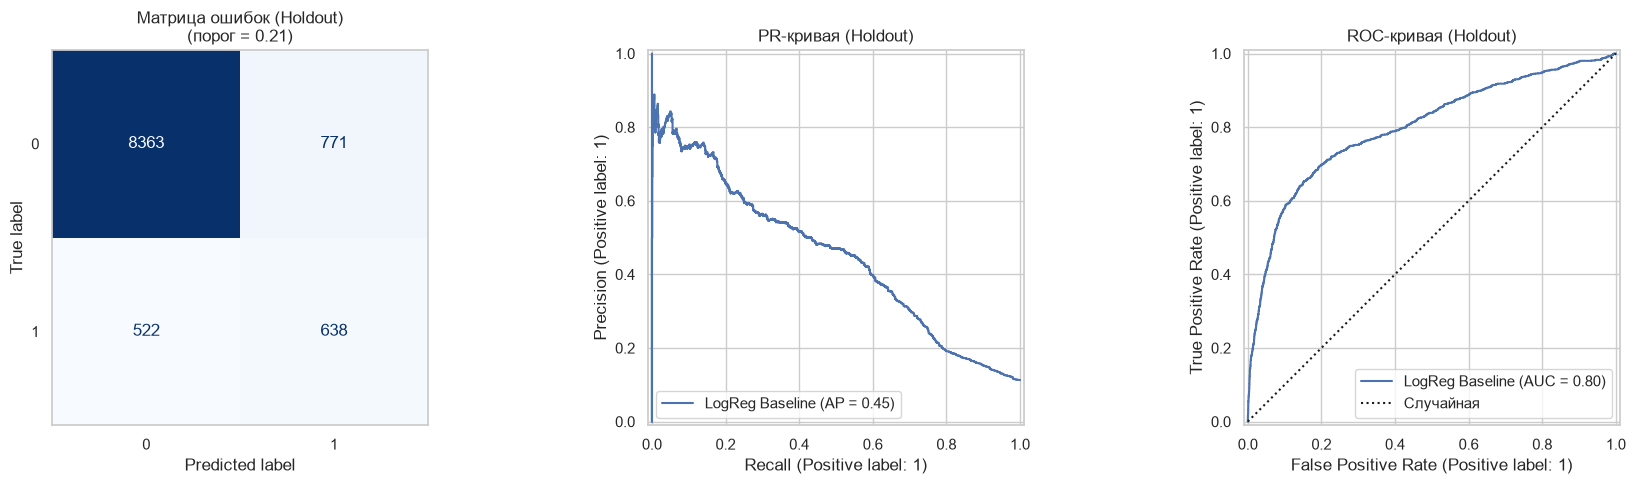

In [4]:
# 1. Подбор порога через честные Out-Of-Fold вероятности на Train
oof_proba = cross_val_predict(best_model, X_train_raw, y_train, cv=cv_strategy, method='predict_proba')[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_train, oof_proba)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)
optimal_threshold = thresholds[np.argmax(f1_scores)]

# 2. Финальная оценка на Holdout (тестовой выборке, которую модель не видела)
y_proba_test = best_model.predict_proba(X_test_raw)[:, 1]
y_pred_test = (y_proba_test >= optimal_threshold).astype(int)

def calculate_lift(y_true, y_proba, top_pct=0.1):
    df_lift = pd.DataFrame({'true': y_true, 'proba': y_proba}).sort_values(by='proba', ascending=False)
    top_n = max(1, int(len(df_lift) * top_pct))
    return df_lift.head(top_n)['true'].mean() / y_true.mean()

print(f"ROC-AUC (Holdout): {roc_auc_score(y_test, y_proba_test):.4f}")
print(f"PR-AUC (Holdout): {average_precision_score(y_test, y_proba_test):.4f}")
print(f"Lift@10% (Holdout): {calculate_lift(y_test, y_proba_test):.4f}\n")
print(f"Оптимальный порог: {optimal_threshold:.3f}\n")
print(classification_report(y_test, y_pred_test, target_names=["Отказ (0)", "Согласие (1)"]))

# Визуализация метрик
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Матрица ошибок (Holdout)\n(порог = {optimal_threshold:.2f})")
axes[0].grid(False)

PrecisionRecallDisplay.from_predictions(y_test, y_proba_test, ax=axes[1], name='LogReg Baseline')
axes[1].set_title("PR-кривая (Holdout)")

RocCurveDisplay.from_predictions(y_test, y_proba_test, ax=axes[2], name='LogReg Baseline')
axes[2].plot([0, 1], [0, 1], 'k:', label='Случайная')
axes[2].legend(loc='lower right')
axes[2].set_title("ROC-кривая (Holdout)")

plt.tight_layout()
plt.show()

## 4. Интерпретация модели: веса признаков и Bivariate анализ

Маркетологам важно понимать, почему модель рекомендует одних клиентов и бракует других. Поскольку перед подачей в логистическую регрессию все числовые данные были отмасштабированы, мы можем напрямую оценивать важность признаков по размеру их коэффициентов (весов).

Строим два графика:
1. Глобальная важность: Топ-10 признаков с самыми большими по модулю коэффициентами. Положительный вес увеличивает шанс на согласие, отрицательный - уменьшает.
2. Сравнение конверсии по категориям: Прямое визуальное сравнение доли согласий в зависимости от канала связи (например, как тип связи влияет на успешность звонка).

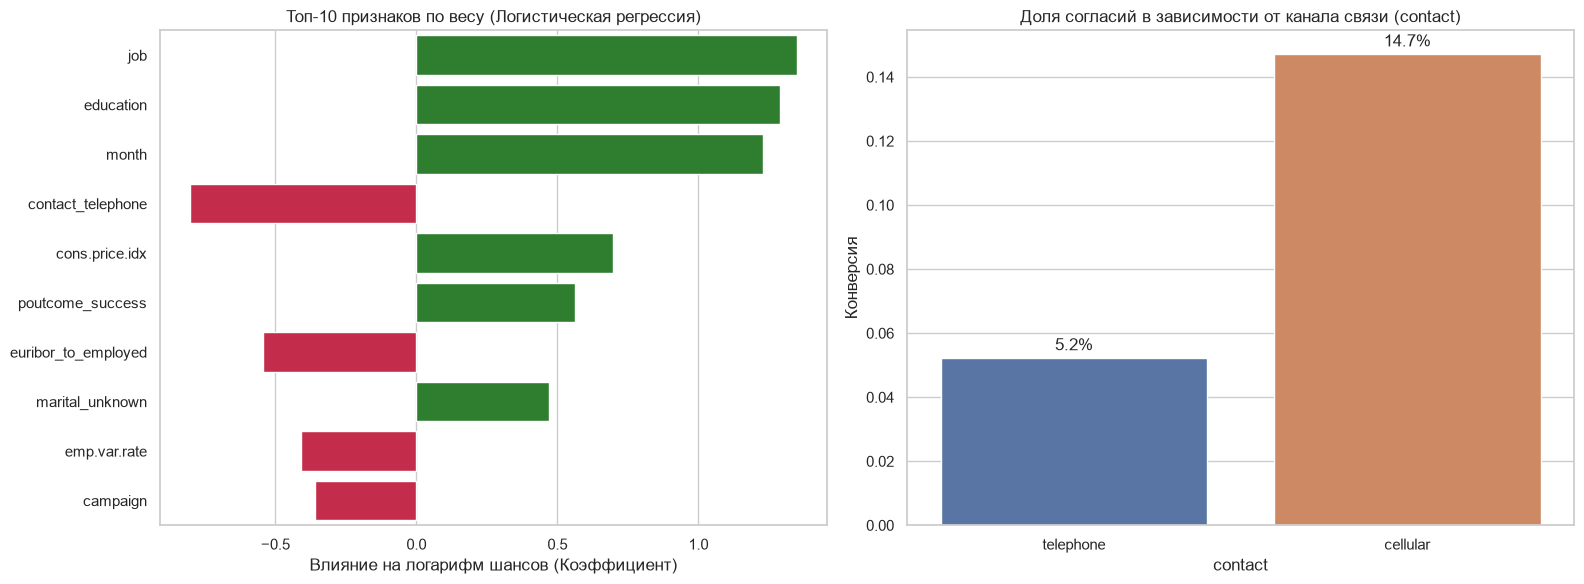

In [10]:
# 1. Извлечение весов признаков из линейной модели
classifier = best_model.named_steps['classifier']
preprocessor = best_model.named_steps['preprocessor']

ohe_cols = preprocessor.named_transformers_['cat_ohe'].get_feature_names_out(other_cats).tolist()
all_feature_names = numerical_features + ohe_cols + high_card_cats

coefs = pd.DataFrame({
    'feature': all_feature_names,
    'importance': classifier.coef_[0]
}).sort_values(by='importance', key=abs, ascending=False)

# Формируем цвета: зеленый для положительных коэффициентов, красный для отрицательных
top_coefs = coefs.head(10)
bar_colors = ['forestgreen' if x > 0 else 'crimson' for x in top_coefs['importance']]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=top_coefs, x='importance', y='feature', hue='feature', palette=bar_colors, ax=axes[0], legend=False)
axes[0].set_title('Топ-10 признаков по весу (Логистическая регрессия)')
axes[0].set_xlabel('Влияние на логарифм шансов (Коэффициент)')
axes[0].set_ylabel('')

# 2. Сравнение конверсии по каналу связи (contact)
df_analysis = X_train_raw.copy()
df_analysis['target'] = y_train

sns.barplot(data=df_analysis, x='contact', y='target', hue='contact', ax=axes[1], legend=False, errorbar=None)
axes[1].set_title('Доля согласий в зависимости от канала связи (contact)')
axes[1].set_ylabel('Конверсия')
for col in axes[1].containers:
    axes[1].bar_label(col, fmt=lambda x: f'{x:.1%}', padding=3)

plt.tight_layout()
plt.show()

## 5. Выводы

1. Надежность пайплайна: Базовая модель логистической регрессии обучена с использованием `StratifiedKFold` (3 фолда) для подбора гиперпараметров и вычисления Out-Of-Fold вероятностей. Генерация признаков, `TargetEncoder` и стандартизация вынесены внутрь `Pipeline`, что исключает утечку данных (data leakage). По результатам `GridSearchCV` лучшими параметрами стали `C = 1.0` и `class_weight = None`.

2. Проверка на Holdout: Финальные метрики сняты на отложенной выборке (25%), которую модель не видела на этапе настройки. На тесте получили `ROC-AUC = 0.800`, `PR-AUC = 0.449` и `Lift@10% = 4.40` - конверсия в топ-10% клиентов по оценке модели в 4.4 раза выше, чем при случайном обзвоне базы.

3. Оптимальный порог: Порог принятия решения (`0.210`) подобран по максимуму метрики F1-score на Out-Of-Fold предсказаниях, что исключает переобучение порога под тест. На Holdout с этим порогом модель находит 55% согласных клиентов (`Recall = 0.55`) при точности 45% (`Precision = 0.45`, `F1 = 0.50`).

4. Интерпретация результатов:
    * Наибольший положительный вес в линейной модели получили категориальные признаки профиля клиента (`job`, `education`) и фактор месяца (`month`).

    * Значительное негативное влияние оказывает стационарный телефон (`contact_telephone`) и макроэкономические показатели (`euribor_to_employed`, `emp.var.rate`). Их крупные отрицательные коэффициенты означают, что при звонке на домашний номер или изменении макроэкономических условий (росте ставки Euribor и уровня занятости) вероятность согласия заметно падает.
    
    * Сравнение конверсии по каналу связи подтверждает веса модели: звонки на мобильный (`cellular`) конвертируются существенно лучше, чем на стационарный (`telephone`), поэтому этот признак важен для первичной сегментации базы.